##QUESTION 1

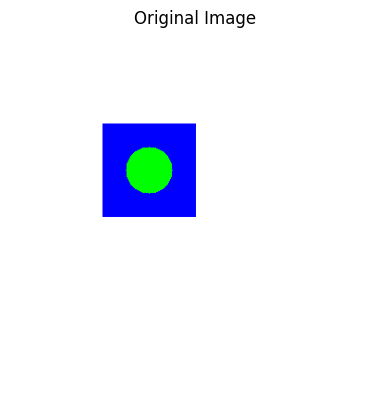

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a sample image
img = np.full((400, 400, 3), 255, dtype=np.uint8)

# Draw a blue rectangle
cv2.rectangle(img, (100, 100), (200, 200),
              (255, 0, 0), -1)

# Draw a green circle
cv2.circle(img, (150, 150), 25,
           (0, 255, 0), -1)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

PART a)

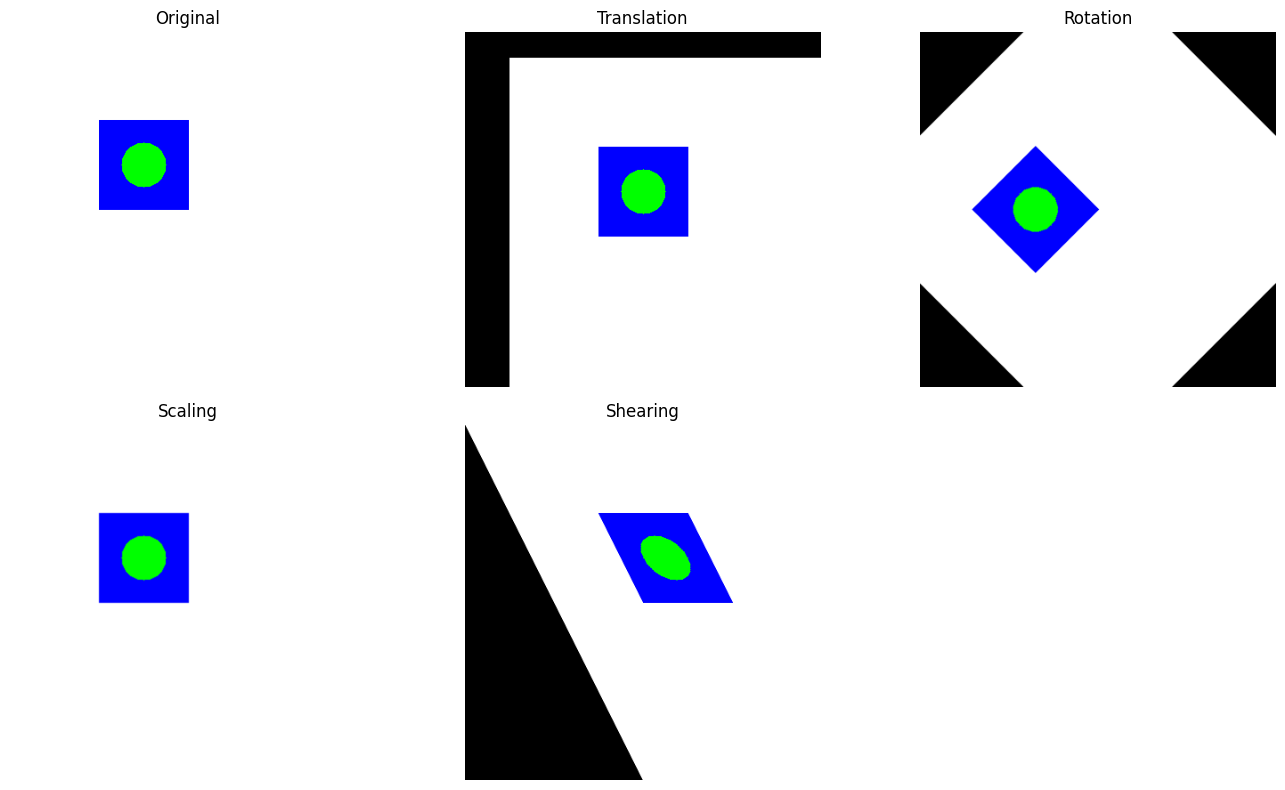

In [8]:
h, w = img.shape[:2]

# 1. Translation: move right by 50, down by 30
M_translate = np.float32([
    [1, 0, 50],
    [0, 1, 30]
])

translated = cv2.warpAffine(
    img, M_translate, (w, h)
)

# 2. Rotation: rotate 45 degrees around image center
center = (w // 2, h // 2)

M_rotate = cv2.getRotationMatrix2D(
    center, 45, 1.0
)

rotated = cv2.warpAffine(
    img, M_rotate, (w, h)
)

# 3. Scaling: enlarge by 1.5 times
scaled = cv2.resize(
    img, None,
    fx=1.5, fy=1.5,
    interpolation=cv2.INTER_LINEAR
)

# 4. Horizontal shearing
M_shear = np.float32([
    [1, 0.5, 0],
    [0, 1,   0]
])

sheared = cv2.warpAffine(
    img, M_shear, (w, h)
)

# Display all results
images = [
    ("Original", img),
    ("Translation", translated),
    ("Rotation", rotated),
    ("Scaling", scaled),
    ("Shearing", sheared)
]

plt.figure(figsize=(14, 8))

for i, (title, image) in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

PART b)

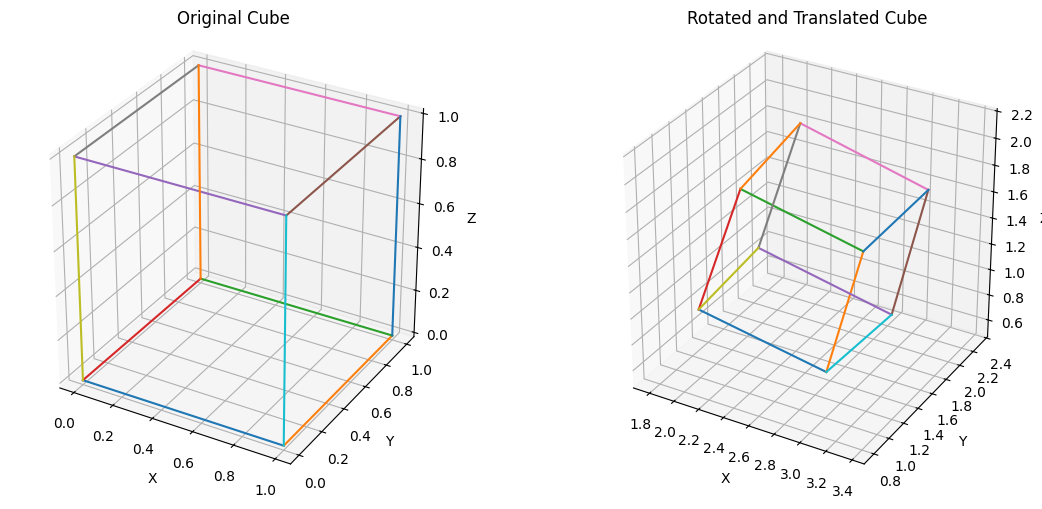

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Eight vertices of a cube
points = np.array([
    [0, 0, 0],
    [1, 0, 0],
    [1, 1, 0],
    [0, 1, 0],
    [0, 0, 1],
    [1, 0, 1],
    [1, 1, 1],
    [0, 1, 1]
], dtype=float)

# Edges connecting the cube vertices
edges = [
    (0, 1), (1, 2), (2, 3), (3, 0),
    (4, 5), (5, 6), (6, 7), (7, 4),
    (0, 4), (1, 5), (2, 6), (3, 7)
]

# Rotation angles in radians
ax = np.radians(30)
ay = np.radians(30)
az = np.radians(30)

# Rotation matrices
Rx = np.array([
    [1, 0, 0],
    [0, np.cos(ax), -np.sin(ax)],
    [0, np.sin(ax),  np.cos(ax)]
])

Ry = np.array([
    [ np.cos(ay), 0, np.sin(ay)],
    [0, 1, 0],
    [-np.sin(ay), 0, np.cos(ay)]
])

Rz = np.array([
    [np.cos(az), -np.sin(az), 0],
    [np.sin(az),  np.cos(az), 0],
    [0, 0, 1]
])

# Apply rotation around X, Y, and Z
R = Rz @ Ry @ Rx

# Rotate every vertex
rotated_points = points @ R.T

# Translate the rotated cube
translation = np.array([2, 1, 1])
transformed_points = rotated_points + translation

# Plot original and transformed cubes
fig = plt.figure(figsize=(12, 5))

for plot_no, data, title in [
    (1, points, "Original Cube"),
    (2, transformed_points, "Rotated and Translated Cube")
]:
    ax3d = fig.add_subplot(1, 2, plot_no, projection="3d")

    for i, j in edges:
        ax3d.plot(
            data[[i, j], 0],
            data[[i, j], 1],
            data[[i, j], 2]
        )

    ax3d.set_title(title)
    ax3d.set_xlabel("X")
    ax3d.set_ylabel("Y")
    ax3d.set_zlabel("Z")
    ax3d.set_box_aspect([1, 1, 1])

plt.tight_layout()
plt.show()

PART c)

In [10]:
import numpy as np

# Original 2D point
point = np.array([3, 4])

# Convert to homogeneous coordinates
point_h = np.array([3, 4, 1])

print("Original point:", point)
print("Homogeneous point:", point_h)

# Translation by 5 in X and 2 in Y
T = np.array([
    [1, 0, 5],
    [0, 1, 2],
    [0, 0, 1]
])

# Apply translation
result_h = T @ point_h

# Convert back to ordinary 2D coordinates
result = result_h[:2] / result_h[2]

print("Transformed homogeneous point:", result_h)
print("Transformed 2D point:", result)

Original point: [3 4]
Homogeneous point: [3 4 1]
Transformed homogeneous point: [8 6 1]
Transformed 2D point: [8. 6.]


PART d)

Affine matrix:
 [[   1.05882353   -0.27777778   43.07189542]
 [   0.29411765    1.38888889 -112.41830065]]


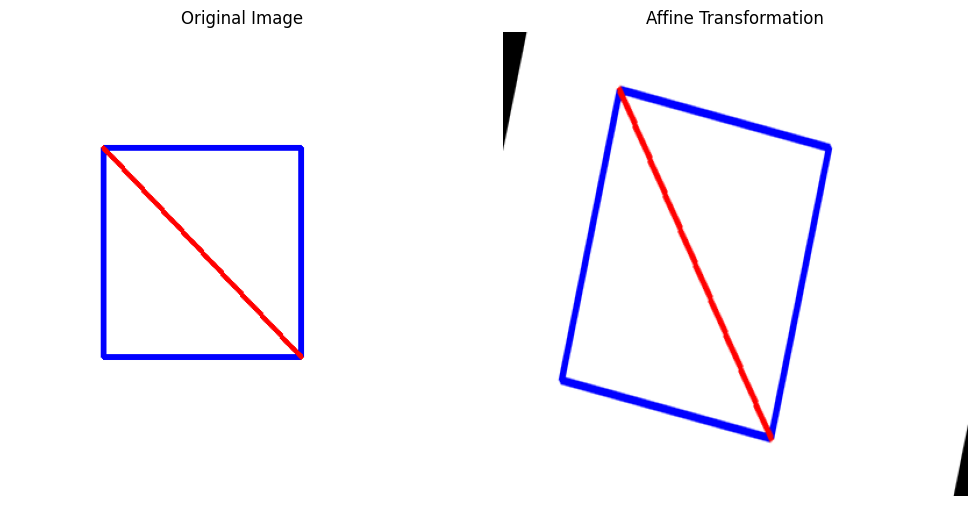

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a white image
img = np.full((400, 400, 3), 255, dtype=np.uint8)

# Draw a rectangle outline
cv2.rectangle(img, (80, 100), (250, 280),
              (255, 0, 0), 3)

# Draw a straight diagonal line
cv2.line(img, (80, 100), (250, 280),
         (0, 0, 255), 3)

# Three corresponding points define an affine transformation
src_pts = np.float32([
    [80, 100],
    [250, 100],
    [80, 280]
])

dst_pts = np.float32([
    [100, 50],
    [280, 100],
    [50, 300]
])

# Compute the affine transformation matrix
M = cv2.getAffineTransform(src_pts, dst_pts)

print("Affine matrix:\n", M)

# Apply transformation
h, w = img.shape[:2]

affine_img = cv2.warpAffine(
    img, M, (w, h)
)

# Display original and transformed images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(affine_img, cv2.COLOR_BGR2RGB))
plt.title("Affine Transformation")
plt.axis("off")

plt.tight_layout()
plt.show()

PART e)

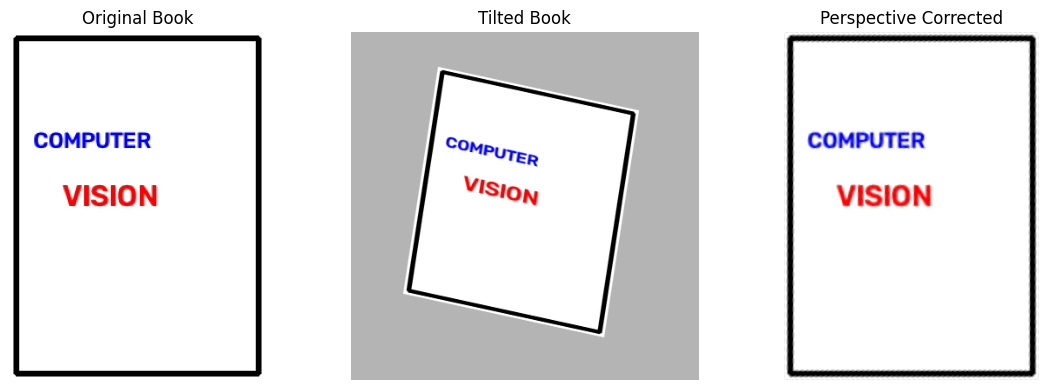

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Create a rectangular book cover
book = np.full((300, 220, 3), 255, dtype=np.uint8)

cv2.rectangle(book, (5, 5), (214, 294),
              (0, 0, 0), 3)

cv2.putText(book, "COMPUTER",
            (20, 100),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65, (255, 0, 0), 2)

cv2.putText(book, "VISION",
            (45, 150),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.9, (0, 0, 255), 2)

# Step 2: Create a larger canvas
canvas = np.full((400, 400, 3), 180, dtype=np.uint8)

# Four corners of the original book
src = np.float32([
    [0, 0],
    [219, 0],
    [219, 299],
    [0, 299]
])

# Four corners of the tilted book
dst = np.float32([
    [100, 40],
    [330, 90],
    [290, 350],
    [60, 300]
])

# Step 3: Simulate perspective distortion
H_tilt = cv2.getPerspectiveTransform(src, dst)

tilted = cv2.warpPerspective(
    book, H_tilt, (400, 400),
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=(180, 180, 180)
)

# Step 4: Define the tilted corners as source points
# and the desired rectangular corners as destination points
src_correct = dst.copy()

dst_correct = np.float32([
    [0, 0],
    [219, 0],
    [219, 299],
    [0, 299]
])

# Step 5: Compute the correction homography
H_correct = cv2.getPerspectiveTransform(
    src_correct, dst_correct
)

# Step 6: Rectify the tilted image
corrected = cv2.warpPerspective(
    tilted, H_correct, (220, 300)
)

# Step 7: Display all three stages
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(book, cv2.COLOR_BGR2RGB))
plt.title("Original Book")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(tilted, cv2.COLOR_BGR2RGB))
plt.title("Tilted Book")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(corrected, cv2.COLOR_BGR2RGB))
plt.title("Perspective Corrected")
plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
##QUESTION 2

In [ ]:
import cv2
import numpy as np

def apply_perspective_transform(img, src_pts):
    # Image dimensions: height and width
    h, w = img.shape[:2]

    # src_pts: four corners of the tilted object
    # Order: top-left, top-right, bottom-right, bottom-left

    # Destination: perfect rectangle
    dst_pts = np.float32([
        [0, 0],
        [w - 1, 0],
        [w - 1, h - 1],
        [0, h - 1]
    ])

    # Calculate the perspective transformation matrix
    M = cv2.getPerspectiveTransform(
        np.float32(src_pts),
        dst_pts
    )

    # Apply inverse perspective correction
    corrected = cv2.warpPerspective(
        img, M, (w, h)
    )

    return corrected

In [ ]:
##QUESTION 3

In [ ]:
import cv2
import numpy as np

# Step 1: Load saved calibration parameters
data = np.load("camera_calibration.npz")

camera_matrix = data["camera_matrix"]
dist_coeffs = data["dist_coeffs"]

# Step 2: Open webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Error: Could not open webcam")
    exit()

# Step 3: Process video frames continuously
while True:

    # Read a frame
    ret, frame = cap.read()

    if not ret:
        print("Error: Could not read frame")
        break

    # Step 4: Undistort the frame
    undistorted = cv2.undistort(
        frame,
        camera_matrix,
        dist_coeffs
    )

    # Step 5: Display original and corrected frames
    cv2.imshow("Original Feed", frame)
    cv2.imshow("Undistorted Feed", undistorted)

    # Press q to exit
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Step 6: Release resources
cap.release()
cv2.destroyAllWindows()